<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

**Name:** Avaneesh Rajesh Shetty  
**USN:** 1RUA25CSE0096  
**Sec:** G  

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [1]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
%matplotlib inline

In [2]:
# Verify the by-hand worked example (Section 4 and 5)
pts = np.array([[1, 1], [1.5, 2], [3, 4], [5, 7], [3.5, 5], [4.5, 5], [3.5, 4.5]])
names = list("ABCDEFG")
cent = pts[[0, 3]].copy()                       # mu1 = A, mu2 = D

for it in range(1, 10):
    d = np.sqrt(((pts[:, None] - cent[None]) ** 2).sum(axis=2))
    lab = d.argmin(axis=1)                      # ties -> first centroid
    print(f"Iteration {it}: clusters =", {f"C{j+1}": [n for n, l in zip(names, lab) if l == j] for j in range(2)})
    print(np.round(d, 3))
    new = np.array([pts[lab == j].mean(axis=0) for j in range(2)])
    print("new centroids:", new.round(3).tolist(), "\n")
    if np.allclose(new, cent): break
    cent = new

wcss = sum(((pts[lab == j] - cent[j]) ** 2).sum() for j in range(2))
print("Final WCSS:", wcss)

dist = lambda p, q: np.sqrt(((p - q) ** 2).sum())
a = dist(pts[0], pts[1])
b = np.mean([dist(pts[0], pts[i]) for i in range(2, 7)])
print(f"a(A)={a:.3f}, b(A)={b:.3f}, s(A)={(b - a) / max(a, b):.3f}")
print("sklearn silhouette (all points):", round(silhouette_score(pts, lab), 4))

km_demo = KMeans(n_clusters=2, init=pts[[0, 3]], n_init=1).fit(pts)
print("sklearn labels:", km_demo.labels_, "| inertia_:", round(km_demo.inertia_, 3))

Iteration 1: clusters = {'C1': ['A', 'B', 'C'], 'C2': ['D', 'E', 'F', 'G']}
[[0.    7.211]
 [1.118 6.103]
 [3.606 3.606]
 [7.211 0.   ]
 [4.717 2.5  ]
 [5.315 2.062]
 [4.301 2.915]]
new centroids: [[1.833, 2.333], [4.125, 5.375]] 

Iteration 2: clusters = {'C1': ['A', 'B'], 'C2': ['C', 'D', 'E', 'F', 'G']}
[[1.572 5.376]
 [0.471 4.276]
 [2.034 1.777]
 [5.64  1.846]
 [3.145 0.729]
 [3.771 0.53 ]
 [2.734 1.075]]
new centroids: [[1.25, 1.5], [3.9, 5.1]] 

Iteration 3: clusters = {'C1': ['A', 'B'], 'C2': ['C', 'D', 'E', 'F', 'G']}
[[0.559 5.022]
 [0.559 3.92 ]
 [3.052 1.421]
 [6.657 2.195]
 [4.161 0.412]
 [4.776 0.608]
 [3.75  0.721]]
new centroids: [[1.25, 1.5], [3.9, 5.1]] 

Final WCSS: 8.524999999999999
a(A)=1.118, b(A)=5.030, s(A)=0.778
sklearn silhouette (all points): 0.645
sklearn labels: [0 0 1 1 1 1 1] | inertia_: 8.525


# Load the data set

In [3]:
df = pd.read_csv("income.csv")
display(df.head(8))
display(df.describe())

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000


,Age,Income($)
count,22.000000,22.000000
mean,34.818182,90431.818182
std,5.901060,43505.964412
min,26.000000,45000.000000
25%,29.000000,58500.000000
50%,36.500000,67500.000000
75%,39.750000,135250.000000
max,43.000000,162000.000000


# Plot the scater plot

Text(0, 0.5, 'Income($)')

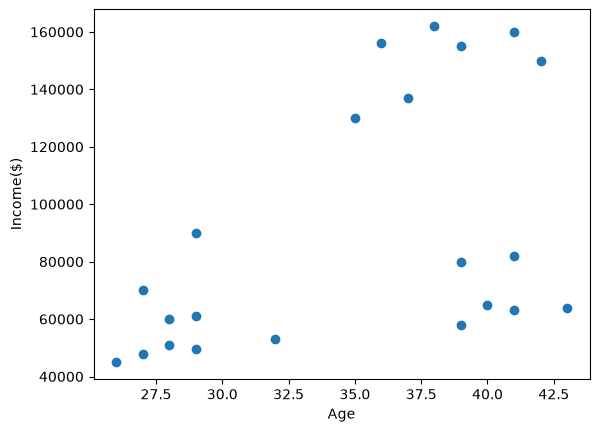

In [4]:
plt.scatter(df.Age,df["Income($)"])
plt.xlabel("Age")
plt.ylabel("Income($)")

By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [5]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[["Age","Income($)"]])
y_predicted

array([0, 2, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 0],
      dtype=int32)

# Assign the cluster table to the samples 

In [6]:
df["cluster"] = y_predicted
df.head(10)

,Name,Age,Income($),cluster
0,Rob,27,70000,0
1,Michael,29,90000,2
2,Mohan,29,61000,0
3,Ismail,28,60000,0
4,Kory,42,150000,1
5,Gautam,39,155000,1
6,David,41,160000,1
7,Andrea,38,162000,1
8,Brad,36,156000,1
9,Angelina,35,130000,1


In [7]:
km.cluster_centers_

array([[3.24166667e+01, 5.72916667e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.63333333e+01, 8.40000000e+04]])

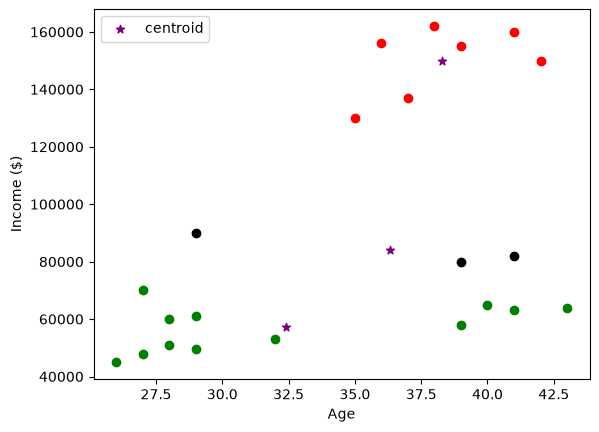

In [8]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()

The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [9]:
# Min-max worked example for Rob (before scaling)
age_min, age_max = df.Age.min(), df.Age.max()
inc_min, inc_max = df['Income($)'].min(), df['Income($)'].max()
print("Age range:", age_min, "->", age_max, "| Income range:", inc_min, "->", inc_max)
print("Rob Age'   =", round((27 - age_min) / (age_max - age_min), 4))
print("Rob Income'=", round((70000 - inc_min) / (inc_max - inc_min), 4))

Age range: 26 -> 43 | Income range: 45000 -> 162000
Rob Age'   = 0.0588
Rob Income'= 0.2137


In [10]:
scaler = MinMaxScaler()

df[['Income($)', 'Age']] = scaler.fit_transform(
    df[['Income($)', 'Age']]
)

In [11]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,0
1,Michael,0.176471,0.384615,2
2,Mohan,0.176471,0.136752,0
3,Ismail,0.117647,0.128205,0
4,Kory,0.941176,0.897436,1


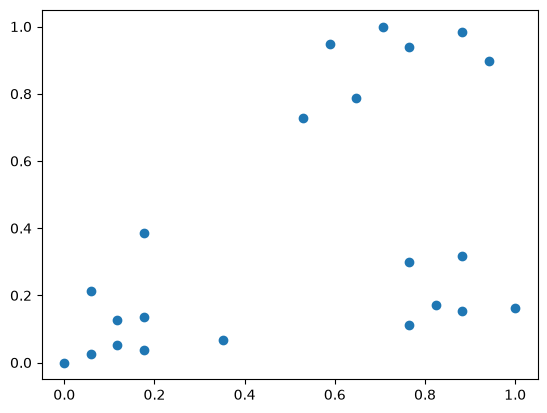

In [12]:
plt.scatter(df.Age,df['Income($)'])

In [13]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [14]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0


In [15]:
km.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

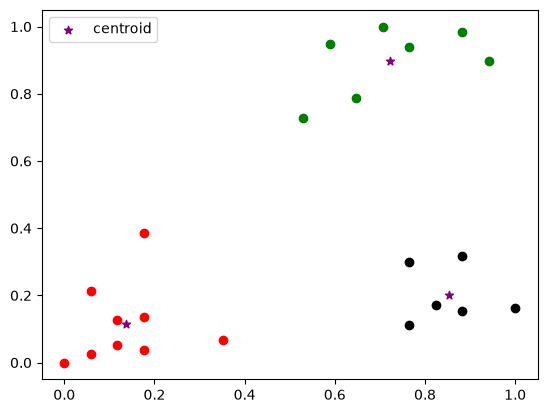

In [16]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores



---



In [17]:
X = df[["Age","Income($)"]]
k_range = range(2,10)

sse,silhouette_scores = [],[]

for k in k_range:
    km = KMeans(n_clusters=k,random_state=42, n_init=10).fit(X)
    sse.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X,km.labels_))

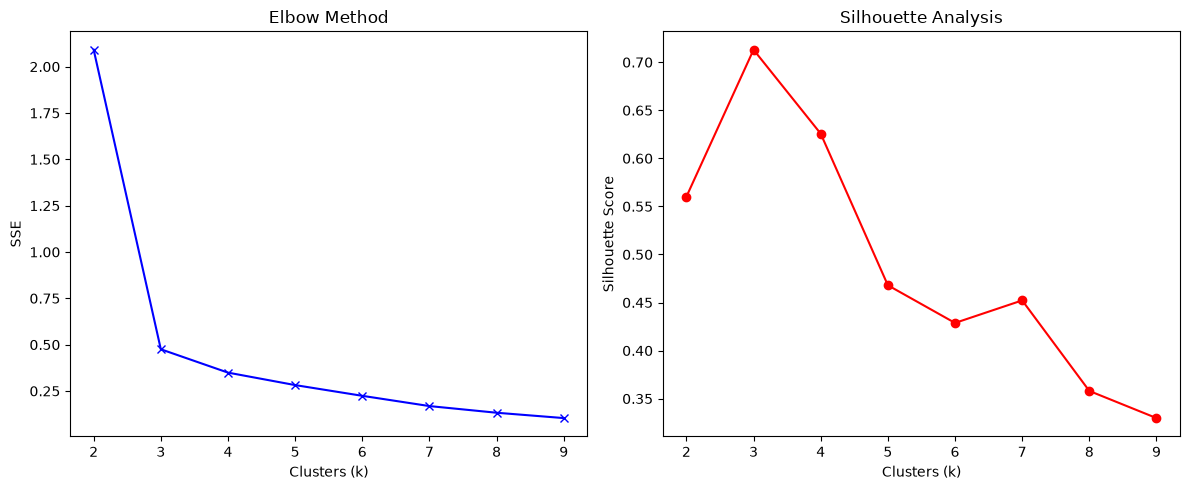

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
plt.show()

# load the dataset

In [19]:
df = pd.read_csv("income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [20]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [21]:
def kmeans(X, k, max_iters=100):
    np.random.seed(42)
    centroids = X[np.random.choice(len(X), k, replace=False)].copy()

    for _ in range(max_iters):
        # assignment step: nearest centroid by squared Euclidean distance
        labels = np.argmin(np.array([np.sum((X - c) ** 2, axis=1) for c in centroids]).T, axis=1)
        # update step: mean of each cluster (keep old centroid if a cluster is empty)
        new_centroids = np.array([X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
                                  for i in range(k)])
        if np.allclose(centroids, new_centroids): break
        centroids = new_centroids

    labels = np.argmin(np.array([np.sum((X - c) ** 2, axis=1) for c in centroids]).T, axis=1)
    return centroids, labels

In [22]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        2
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.98550535 -0.51205261]
 [ 0.60143983  1.40141653]]


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

In [23]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

wine = load_wine()
X, y_true = wine.data, wine.target      # y_true is used ONLY for ARI / NMI in Step 6

### Step 2 — Explore and preprocess

In [24]:
df_wine = pd.DataFrame(X, columns=wine.feature_names)
print("Shape:", df_wine.shape)
display(df_wine.head())
display(df_wine.describe().T[['min', 'max', 'mean', 'std']])

Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,min,max,mean,std
alcohol,11.03,14.83,13.000618,0.811827
malic_acid,0.74,5.80,2.336348,1.117146
ash,1.36,3.23,2.366517,0.274344
alcalinity_of_ash,10.60,30.00,19.494944,3.339564
magnesium,70.00,162.00,99.741573,14.282484
total_phenols,0.98,3.88,2.295112,0.625851
flavanoids,0.34,5.08,2.029270,0.998859
nonflavanoid_phenols,0.13,0.66,0.361854,0.124453
proanthocyanins,0.41,3.58,1.590899,0.572359
color_intensity,1.28,13.00,5.058090,2.318286


**Why scaling is necessary.** K-Means is built on Euclidean distance, so every feature contributes to the distance in proportion to its *numeric range*. In the Wine data, `proline` runs from ~278 to ~1680 and `magnesium` from ~70 to ~162, while `hue` sits around 0.5–1.7 and `nonflavanoid_phenols` around 0.1–0.7. Without scaling, the squared difference in `proline` is millions of times bigger than the one in `hue`, so the clusters would be decided almost entirely by proline (the same problem we saw with Income vs Age earlier). `StandardScaler` rescales each feature to mean 0 and standard deviation 1, so all 13 features get an equal say.

In [25]:
X_scaled = StandardScaler().fit_transform(X)
print("Means ~ 0:", X_scaled.mean(axis=0).round(2))
print("Stds  = 1:", X_scaled.std(axis=0).round(2))

# PCA is used for plotting ONLY - clustering below uses all 13 scaled features
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3))

Means ~ 0: [ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Stds  = 1: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Variance explained by the 2 components: [0.362 0.192]


### Step 3 — K-Means from scratch (NumPy only)

In [26]:
def wcss_scratch(X, centroids, labels):
    """WCSS = sum over clusters of squared distance of each point to its centroid."""
    return sum(np.sum((X[labels == k] - c) ** 2) for k, c in enumerate(centroids))

def assign(X, centroids):
    """Index of the nearest centroid (Euclidean) for every point."""
    d = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)   # (n_points, k)
    return d.argmin(axis=1)

def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centroids = X[rng.choice(len(X), k, replace=False)]           # 1. random data points
        for it in range(1, max_iters + 1):
            labels = assign(X, centroids)                              # 2. assign
            new = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j]
                            for j in range(k)])                        # 3. update
            moved = not np.allclose(new, centroids)
            centroids = new
            if not moved: break                                        # 4. converged
        labels = assign(X, centroids)
        w = wcss_scratch(X, centroids, labels)
        if best is None or w < best[2]:                                # 5. keep lowest WCSS
            best = (centroids, labels, w, it)
    return best                                                        # 6. centroids, labels, wcss, n_iter

centroids_s, labels_s, wcss_s, iters_s = kmeans_scratch(X_scaled, 3)
print("Scratch  -> WCSS:", round(wcss_s, 3), "| iterations (best run):", iters_s)
print("Cluster sizes:", np.bincount(labels_s))

Scratch  -> WCSS: 1277.928 | iterations (best run): 3
Cluster sizes: [65 62 51]


⭐ **Bonus — silhouette score from scratch.** For each point $a(i)$ is the mean distance to the other points of its own cluster and $b(i)$ the smallest mean distance to another cluster; a point alone in its cluster gets $s(i)=0$.

In [27]:
def silhouette_scratch(X, labels):
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))   # pairwise distances
    ks = np.unique(labels)
    s = np.zeros(len(X))
    for i in range(len(X)):
        own = labels == labels[i]
        if own.sum() == 1: continue
        a = D[i, own].sum() / (own.sum() - 1)                          # excludes d(i,i)=0
        b = min(D[i, labels == k].mean() for k in ks if k != labels[i])
        s[i] = (b - a) / max(a, b)
    return s.mean()

print("Scratch silhouette:", round(silhouette_scratch(X_scaled, labels_s), 4))
print("sklearn silhouette:", round(silhouette_score(X_scaled, labels_s), 4))
assert np.isclose(silhouette_scratch(X_scaled, labels_s), silhouette_score(X_scaled, labels_s))

Scratch silhouette: 0.2849
sklearn silhouette: 0.2849


### Step 4 — K-Means with scikit-learn

In [28]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)

print("Centroids shape:", km.cluster_centers_.shape)
print(pd.DataFrame(km.cluster_centers_, columns=wine.feature_names).round(2).T)
print("\ninertia_:", round(km.inertia_, 3))
print("n_iter_ :", km.n_iter_)
print("Cluster sizes:", np.bincount(labels_sk))

Centroids shape: (3, 13)
                                 0     1     2
alcohol                      -0.93  0.16  0.84
malic_acid                   -0.39  0.87 -0.30
ash                          -0.49  0.19  0.36
alcalinity_of_ash             0.17  0.52 -0.61
magnesium                    -0.49 -0.08  0.58
total_phenols                -0.08 -0.98  0.89
flavanoids                    0.02 -1.22  0.98
nonflavanoid_phenols         -0.03  0.73 -0.56
proanthocyanins               0.06 -0.78  0.58
color_intensity              -0.90  0.94  0.17
hue                           0.46 -1.16  0.47
od280/od315_of_diluted_wines  0.27 -1.29  0.78
proline                      -0.75 -0.41  1.13

inertia_: 1277.928
n_iter_ : 7
Cluster sizes: [65 51 62]


### Step 5 — Choose the optimal K (K = 2 to 10)

,K,WCSS scratch,WCSS sklearn,Sil scratch,Sil sklearn
0,2,1659.008,1658.759,0.268,0.259
1,3,1277.928,1277.928,0.285,0.285
2,4,1180.053,1175.428,0.252,0.260
3,5,1105.519,1109.513,0.236,0.202
4,6,1057.499,1046.002,0.205,0.237
5,7,982.894,981.595,0.196,0.204
6,8,964.498,935.201,0.131,0.157
7,9,900.402,889.893,0.158,0.150
8,10,874.188,845.895,0.137,0.144


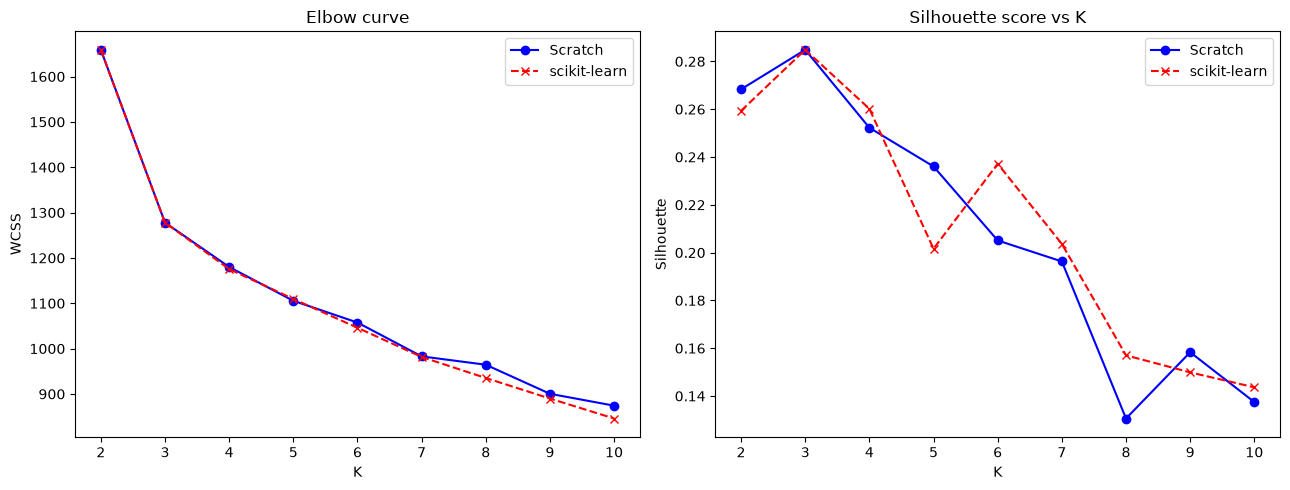

In [29]:
ks = range(2, 11)
wcss_scr, sil_scr, wcss_skl, sil_skl = [], [], [], []

for k in ks:
    c, l, w, _ = kmeans_scratch(X_scaled, k)
    wcss_scr.append(w);  sil_scr.append(silhouette_scratch(X_scaled, l))
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    wcss_skl.append(m.inertia_);  sil_skl.append(silhouette_score(X_scaled, m.labels_))

display(pd.DataFrame({'K': list(ks), 'WCSS scratch': wcss_scr, 'WCSS sklearn': wcss_skl,
                      'Sil scratch': sil_scr, 'Sil sklearn': sil_skl}).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(ks, wcss_scr, 'bo-', label='Scratch')
ax[0].plot(ks, wcss_skl, 'rx--', label='scikit-learn')
ax[0].set(title='Elbow curve', xlabel='K', ylabel='WCSS'); ax[0].legend()
ax[1].plot(ks, sil_scr, 'bo-', label='Scratch')
ax[1].plot(ks, sil_skl, 'rx--', label='scikit-learn')
ax[1].set(title='Silhouette score vs K', xlabel='K', ylabel='Silhouette'); ax[1].legend()
plt.tight_layout(); plt.show()

**Chosen K = 3.**

* **Silhouette:** for both implementations the score peaks at **K = 3** (≈ 0.285) and then falls steadily, so 3 clusters give the best compactness-vs-separation trade-off.
* **Elbow:** WCSS drops sharply from K = 2 to K = 3 and the curve flattens noticeably afterwards (WCSS always decreases as K grows, so we look for the bend, not the minimum).
* **Match with the truth:** yes — the 3 clusters line up with the **3 true cultivars** (see ARI/NMI in Step 6). Note the Wine data has only modest separation in 13 dimensions, which is why the silhouette is ~0.28 and not close to 1.

### Step 6 — Evaluate both models (K = 3)

In [30]:
wcss_val_s = wcss_scratch(X_scaled, centroids_s, labels_s)
sil_s = silhouette_scratch(X_scaled, labels_s)
sil_k = silhouette_score(X_scaled, labels_sk)

results = pd.DataFrame({
    'Type':         ['Internal', 'Internal', 'External', 'External'],
    'Better':       ['Lower', 'Higher (max 1)', 'Higher (max 1)', 'Higher (max 1)'],
    'Scratch':      [wcss_val_s, sil_s,
                     adjusted_rand_score(y_true, labels_s), normalized_mutual_info_score(y_true, labels_s)],
    'scikit-learn': [km.inertia_, sil_k,
                     adjusted_rand_score(y_true, labels_sk), normalized_mutual_info_score(y_true, labels_sk)],
}, index=['WCSS / Inertia', 'Silhouette score', 'ARI', 'NMI']).round(4)
display(results)
print("Agreement between the two clusterings (ARI):", round(adjusted_rand_score(labels_s, labels_sk), 4))

,Type,Better,Scratch,scikit-learn
WCSS / Inertia,Internal,Lower,1277.9285,1277.9285
Silhouette score,Internal,Higher (max 1),0.2849,0.2849
ARI,External,Higher (max 1),0.8975,0.8975
NMI,External,Higher (max 1),0.8759,0.8759


Agreement between the two clusterings (ARI): 1.0


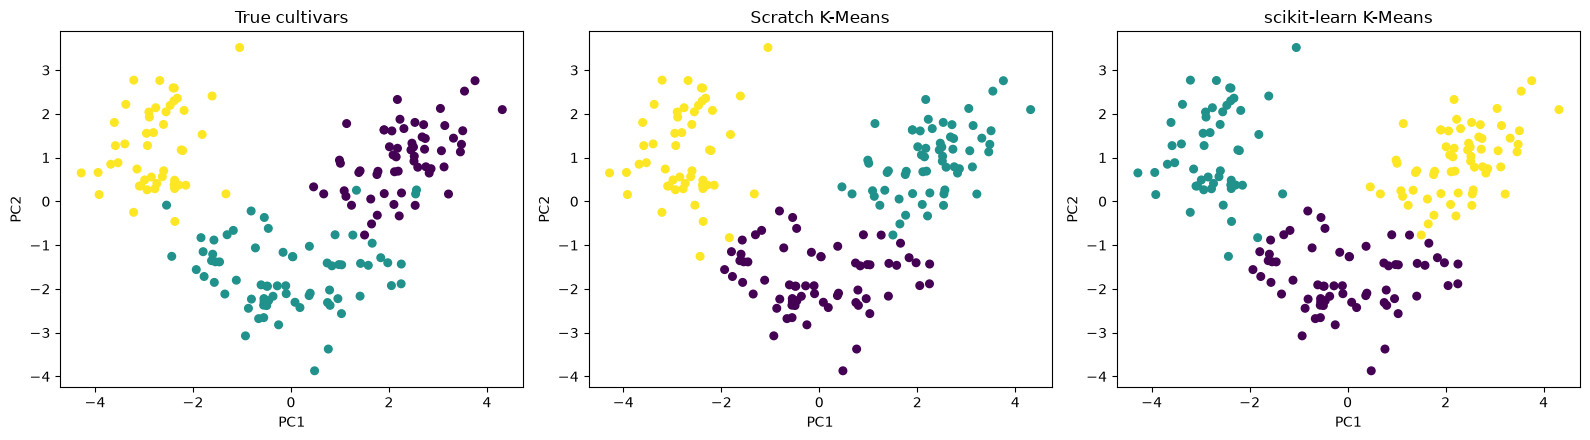

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, lab, t in zip(ax, [y_true, labels_s, labels_sk], ['True cultivars', 'Scratch K-Means', 'scikit-learn K-Means']):
    a.scatter(X_pca[:, 0], X_pca[:, 1], c=lab, cmap='viridis', s=30)
    a.set(title=t, xlabel='PC1', ylabel='PC2')
plt.tight_layout(); plt.show()

**Comparison.** With the same data, K and `random_state`/seed, both implementations reach the **same partition** (agreement ARI = 1.0; only the cluster *numbers* may be permuted, which the metrics ignore), hence identical WCSS ≈ 1277.93, silhouette ≈ 0.285, ARI ≈ 0.897 and NMI ≈ 0.876. The high ARI/NMI show K-Means recovers the three cultivars well using only chemistry; the few mistakes come from wines on the class borders in the PCA plot. For other K (e.g. 4–10) the two can differ slightly because different initialisations land in different local minima — that is why `n_init` restarts matter. The scratch version is simple and readable; scikit-learn's is faster and uses k-means++ initialisation.

### Conclusion

In this lab, K-Means clustering was studied and implemented using both a custom NumPy-based algorithm and scikit-learn. The experiments demonstrated the importance of feature scaling because K-Means relies on Euclidean distance and unscaled features with larger numerical ranges can dominate the clustering process. The custom implementation correctly reproduced the main results of scikit-learn, including comparable WCSS, silhouette scores, and cluster assignments. For the Wine dataset, \(K=3\) provided a reasonable balance between compactness and separation, and the high ARI and NMI scores showed that the clusters corresponded well with the three true wine cultivars. However, the results also highlight that K-Means is sensitive to initialization, assumes roughly spherical clusters, and may converge to local minima; therefore, multiple initializations and suitable evaluation metrics are important when applying it to real-world data.